# 🟢 1. Basics: Perceptron & Linear Decision Boundaries

### *Foundational Deep Learning: From Biological Neurons to Rosenblatt's Perceptron, Logic Gates, and the XOR Problem*

---

## 📌 Module Overview
1. **Biological Inspiration vs. Artificial Neuron**: Dendrites, Soma, Axon, and Synapses.
2. **McCulloch-Pitts Neuron (1943)**: The earliest binary threshold computational model.
3. **Frank Rosenblatt's Perceptron (1958)**: Linear combination $z = \mathbf{w}^T\mathbf{x} + b$ and Heaviside step activation.
4. **The Perceptron Learning Algorithm (PLA)**: Weight and bias update equations, error signal, and hyperplane rotation.
5. **NumPy Implementation from Scratch**: Testing convergence on linearly separable AND and OR logic gates.
6. **The Fatal Flaw: The XOR Problem (Minsky & Papert, 1969)**: Why single-layer perceptrons fail on non-linear functions and how it caused the First AI Winter.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

SEED = 42
np.random.seed(SEED)
print("Environment initialized for Perceptron exploration.")


Environment initialized for Perceptron exploration.


## 1. Mathematical Formulation of the Perceptron
For an input vector $\mathbf{x} = [x_1, x_2, \dots, x_n]^T$ and weight vector $\mathbf{w} = [w_1, w_2, \dots, w_n]^T$ with scalar bias $b$:

$$z = \sum_{i=1}^n w_i x_i + b = \mathbf{w}^T \mathbf{x} + b$$

$$\hat{y} = f(z) = \begin{cases} 1 & \text{if } z \ge 0 \\ 0 & \text{if } z < 0 \end{cases}$$

### The Perceptron Learning Algorithm (PLA) Update Rule:
For each misclassified sample $(\mathbf{x}^{(i)}, y^{(i)})$:
$$w_j \leftarrow w_j + \eta \cdot (y^{(i)} - \hat{y}^{(i)}) \cdot x_j^{(i)}$$
$$b \leftarrow b + \eta \cdot (y^{(i)} - \hat{y}^{(i)})$$

Where $\eta \in (0, 1]$ is the learning rate.


In [2]:
class PerceptronFromScratch:
    """
    Rosenblatt's Perceptron binary classifier implemented from scratch in pure NumPy.
    """
    def __init__(self, learning_rate=0.1, epochs=30):
        self.lr = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = None
        self.errors_per_epoch = []

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0

        for epoch in range(self.epochs):
            errors = 0
            for xi, target in zip(X, y):
                z = np.dot(xi, self.weights) + self.bias
                y_pred = 1 if z >= 0.0 else 0
                delta = target - y_pred
                if delta != 0:
                    self.weights += self.lr * delta * xi
                    self.bias += self.lr * delta
                    errors += 1
            self.errors_per_epoch.append(errors)
            if errors == 0:
                break
        return self

    def predict(self, X):
        z = np.dot(X, self.weights) + self.bias
        return np.where(z >= 0.0, 1, 0)

# Logic Gates Dataset
X_logic = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1])
y_or  = np.array([0, 1, 1, 1])
y_xor = np.array([0, 1, 1, 0])

# Train on AND and OR gates
p_and = PerceptronFromScratch(learning_rate=0.2, epochs=20).fit(X_logic, y_and)
p_or  = PerceptronFromScratch(learning_rate=0.2, epochs=20).fit(X_logic, y_or)

print("AND Predictions:", p_and.predict(X_logic), "Expected:", y_and)
print("OR Predictions: ", p_or.predict(X_logic), "Expected:", y_or)


AND Predictions: [0 0 0 1] Expected: [0 0 0 1]
OR Predictions:  [0 1 1 1] Expected: [0 1 1 1]


## 2. Visualizing Linear Separability & The XOR Barrier
A dataset is **linearly separable** if a single straight line (hyperplane) can partition the feature space such that all instances of Class 1 lie on one side and all instances of Class 0 lie on the other.
* AND and OR are linearly separable.
* XOR is **linearly non-separable**. In 1969, Minsky and Papert proved that no linear hyperplane can ever separate XOR, exposing the limitation of single-layer perceptrons and triggering the First AI Winter.


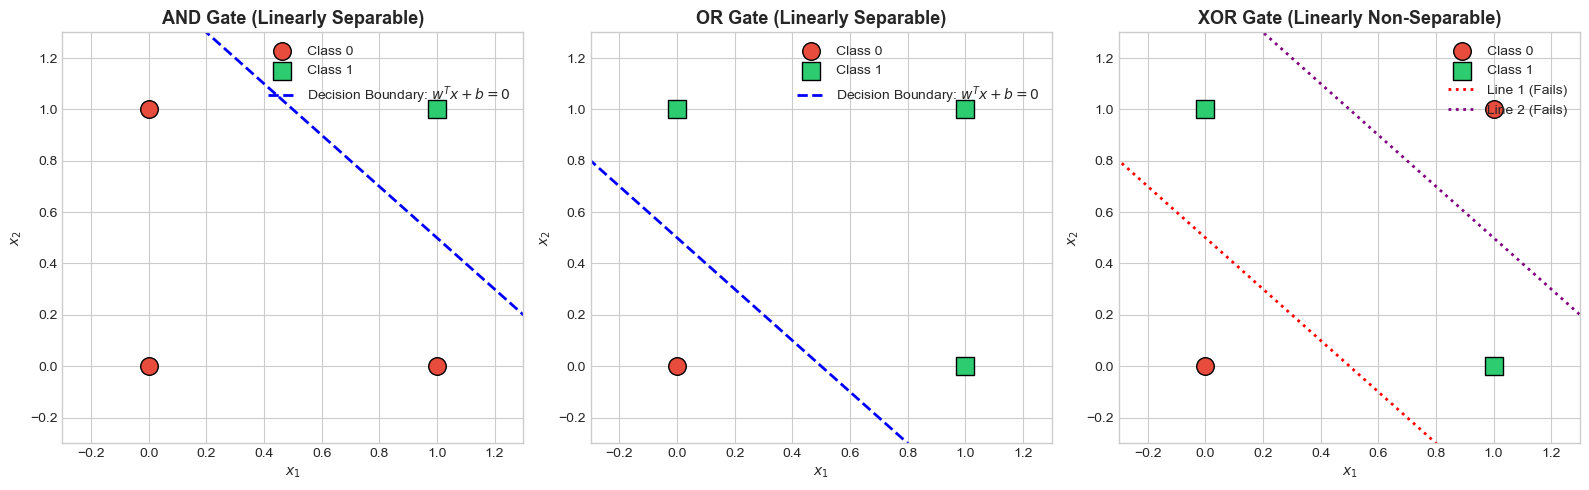

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
titles = ["AND Gate (Linearly Separable)", "OR Gate (Linearly Separable)", "XOR Gate (Linearly Non-Separable)"]
targets = [y_and, y_or, y_xor]
x_vals = np.linspace(-0.5, 1.5, 100)

for idx, (ax, title, y_t) in enumerate(zip(axes, titles, targets)):
    ax.scatter(X_logic[y_t == 0, 0], X_logic[y_t == 0, 1], color='#e74c3c', s=160, edgecolors='black', label='Class 0', zorder=5)
    ax.scatter(X_logic[y_t == 1, 0], X_logic[y_t == 1, 1], color='#2ecc71', s=160, marker='s', edgecolors='black', label='Class 1', zorder=5)
    ax.set_title(title)
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.set_xlim(-0.3, 1.3)
    ax.set_ylim(-0.3, 1.3)

    if idx == 0:
        # AND decision boundary: x1 + x2 = 1.5
        ax.plot(x_vals, 1.5 - x_vals, 'b--', linewidth=2, label='Decision Boundary: $w^Tx+b=0$')
    elif idx == 1:
        # OR decision boundary: x1 + x2 = 0.5
        ax.plot(x_vals, 0.5 - x_vals, 'b--', linewidth=2, label='Decision Boundary: $w^Tx+b=0$')
    else:
        # XOR failure
        ax.plot(x_vals, 0.5 - x_vals, 'r:', linewidth=2, label='Line 1 (Fails)')
        ax.plot(x_vals, 1.5 - x_vals, 'purple', linestyle=':', linewidth=2, label='Line 2 (Fails)')

    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()


## 💡 Core Takeaways
1. The **Perceptron** is the atomic linear unit of neural computing.
2. It reliably finds separating hyperplanes for linearly separable data (Novikoff's theorem).
3. It **fundamentally fails** on non-linear problems like XOR.
4. **The Solution**: Transition to Multi-Layer Perceptrons (MLP) with non-linear activation functions (explored in Notebook 2!).
